## Brief Project (Ringkasan Project)


`Judul`: Employee Attrition Analysis: Identifying Key Factors Associated with Employee Turnover

`Dataset`: HR Analytics Employee Attrition Dataset (https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset)

`Tools`: Python (Pandas, Matplotlib, Seaborn), Tableau

`Output`: PDF Report, Tableau Dashboard, Jupyter Notebook


## Problem Identification (Problem Statement)


`Guideline`:

Analisis ini berfokus pada identifikasi pola dan faktor-faktor yang berkaitan dengan employee attrition (karyawan yang meninggalkan perusahaan), sehingga perusahaan dapat memahami karakteristik karyawan yang memiliki tingkat attrition lebih tinggi.

Masalah bisnisnya apa?
- Perusahaan menghadapi tantangan dalam mempertahankan karyawan (employee retention).
- Belum diketahui karakteristik dan faktor pekerjaan yang berkaitan dengan tingginya attrition, seperti lembur, pendapatan bulanan, kepuasan kerja, masa kerja, dan departemen.
- Perusahaan membutuhkan analisis berbasis data untuk membantu menentukan area yang perlu mendapat perhatian dalam strategi retensi karyawan.

Siapa yang terdampak?
- Human Resources (HR): membutuhkan informasi untuk mengevaluasi strategi retensi dan mengidentifikasi area yang perlu diperbaiki.
- Manajemen perusahaan: membutuhkan informasi untuk mendukung keputusan terkait tenaga kerja dan perencanaan karyawan.
- Karyawan: dapat terdampak oleh tingginya pergantian karyawan, misalnya melalui peningkatan beban kerja atau perubahan komposisi tim.

Kenapa masalah ini penting?
- Pergantian karyawan dapat menimbulkan biaya rekrutmen, seleksi, dan pelatihan karyawan baru.
- Kehilangan karyawan berpengalaman berpotensi mengganggu produktivitas dan kontinuitas operasional.
- Memahami pola attrition dapat membantu perusahaan menyusun strategi retensi yang lebih tepat sasaran.

Research questions:
1. Bagaimana tingkat attrition karyawan secara keseluruhan dan berdasarkan departemen?
2. Karakteristik karyawan apa yang memiliki tingkat attrition relatif tinggi?
3. Bagaimana hubungan antara attrition dengan lembur, pendapatan bulanan, kepuasan kerja, dan masa kerja?
4. Rekomendasi apa yang dapat diberikan kepada HR berdasarkan hasil analisis?

## Background & Business Context

Employee attrition merupakan salah satu tantangan dalam pengelolaan sumber daya manusia karena pergantian karyawan dapat memengaruhi biaya operasional, produktivitas, dan stabilitas organisasi. Perusahaan perlu memahami pola pergantian karyawan untuk mengevaluasi kondisi tenaga kerja dan menentukan prioritas dalam strategi retensi.

Dalam proyek ini, analisis dilakukan menggunakan dataset HR Employee Attrition, yang mencakup informasi mengenai karakteristik demografis, pekerjaan, pendapatan, kepuasan kerja, serta status attrition karyawan.

Analisis ini bertujuan untuk mengidentifikasi pola attrition dan mengeksplorasi faktor-faktor yang berkaitan dengan keputusan karyawan untuk meninggalkan perusahaan. Hasil analisis diharapkan dapat memberikan data-driven insights bagi tim HR dan manajemen dalam mengevaluasi strategi retensi karyawan.

Potensi dampak terhadap bisnis:
- Revenue dan biaya: attrition berpotensi meningkatkan biaya rekrutmen, seleksi, dan pelatihan.
- Operasional: kekosongan posisi dapat mengganggu alur kerja dan meningkatkan beban kerja anggota tim yang tersisa.
- Produktivitas: hilangnya pengalaman dan pengetahuan karyawan dapat memengaruhi efektivitas tim.
- Strategi HR: hasil analisis dapat membantu menentukan departemen atau karakteristik pekerjaan yang perlu diteliti lebih lanjut dalam upaya meningkatkan retensi.

## Data Understanding & Processing

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_csv("/content/WA_Fn-UseC_-HR-Employee-Attrition.csv")

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
print("Ukuran dataset:", df.shape)

print("\nInformasi kolom:")
df.info()

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nJumlah baris duplikat:")
print(df.duplicated().sum())


Ukuran dataset: (1470, 35)

Informasi kolom:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 no

### Memeriksa kolom dengan nilai konstan

In [4]:
# Check columns with only one unique value
constant_columns = [
    column for column in df.columns
    if df[column].nunique(dropna=False) == 1
]

print("Constant columns:", constant_columns)

for column in constant_columns:
    print(f"{column}: {df[column].unique()}")


Constant columns: ['EmployeeCount', 'Over18', 'StandardHours']
EmployeeCount: [1]
Over18: ['Y']
StandardHours: [80]


### Menghapus kolom yang tidak informatif

In [5]:
# Remove constant columns
df = df.drop(columns=constant_columns)

print("Dataset dimensions after removing constant columns:", df.shape)


Dataset dimensions after removing constant columns: (1470, 32)


### Memeriksa kembali missing values dan duplikasi

In [6]:
print("Total missing values:", df.isnull().sum().sum())
print("Total duplicate rows:", df.duplicated().sum())


Total missing values: 0
Total duplicate rows: 0


### Memeriksa nilai unik pada kolom kategorikal

In [7]:
categorical_columns = df.select_dtypes(
    include=["object"]
).columns

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))



Attrition:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

BusinessTravel:
BusinessTravel
Travel_Rarely        1043
Travel_Frequently     277
Non-Travel            150
Name: count, dtype: int64

Department:
Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64

EducationField:
EducationField
Life Sciences       606
Medical             464
Marketing           159
Technical Degree    132
Other                82
Human Resources      27
Name: count, dtype: int64

Gender:
Gender
Male      882
Female    588
Name: count, dtype: int64

JobRole:
JobRole
Sales Executive              326
Research Scientist           292
Laboratory Technician        259
Manufacturing Director       145
Healthcare Representative    131
Manager                      102
Sales Representative          83
Research Director             80
Human Resources               52
Name: count, dtype: int64

MaritalStatus:
MaritalStatus
Married  

In [8]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0
JobSatisfaction,1470.0,2.728571,1.102846,1.0,2.00,3.0,4.00,4.0


In [9]:
print("Final dataset dimensions:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())


Final dataset dimensions: (1470, 32)
Missing values: 0
Duplicate rows: 0


## Exploratory Data Analysis (EDA)

### Overall Employee Attrition

- Berapa proporsi karyawan yang keluar dibandingkan dengan karyawan yang masih bertahan dalam dataset?



- Apakah distribusi status attrition seimbang?

In [10]:
# Count employees by attrition status
attrition_counts = df["Attrition"].value_counts()

# Calculate percentage
attrition_percentage = df["Attrition"].value_counts(normalize=True) * 100

# Combine results into a summary table
attrition_summary = pd.DataFrame({
    "Employee Count": attrition_counts,
    "Percentage (%)": attrition_percentage.round(2)
})

display(attrition_summary)


,Employee Count,Percentage (%)
Attrition,,
No,1233,83.88
Yes,237,16.12


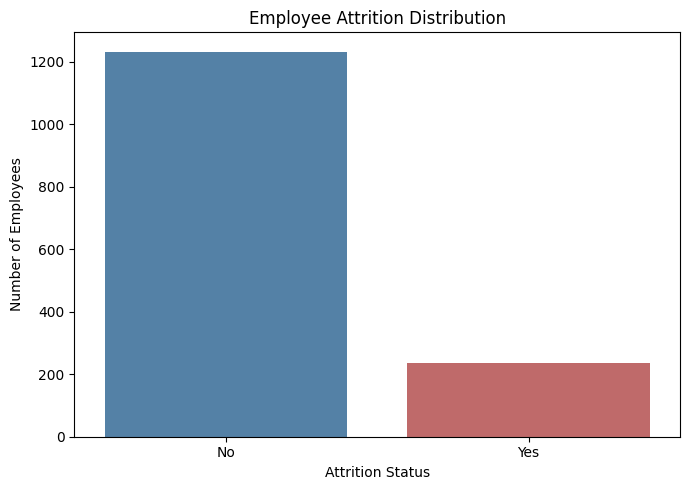

In [11]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Attrition",
    hue="Attrition",
    order=["No", "Yes"],
    palette={"No": "steelblue", "Yes": "indianred"},
    legend=False
)

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition Status")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()


### Analisis attrition berdasarkan departemen

In [12]:
department_attrition = (
    df.groupby("Department")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
    .round(2)
    .reset_index(name="Attrition Rate (%)")
)

display(department_attrition)


,Department,Attrition Rate (%)
0,Sales,20.63
1,Human Resources,19.05
2,Research & Development,13.84


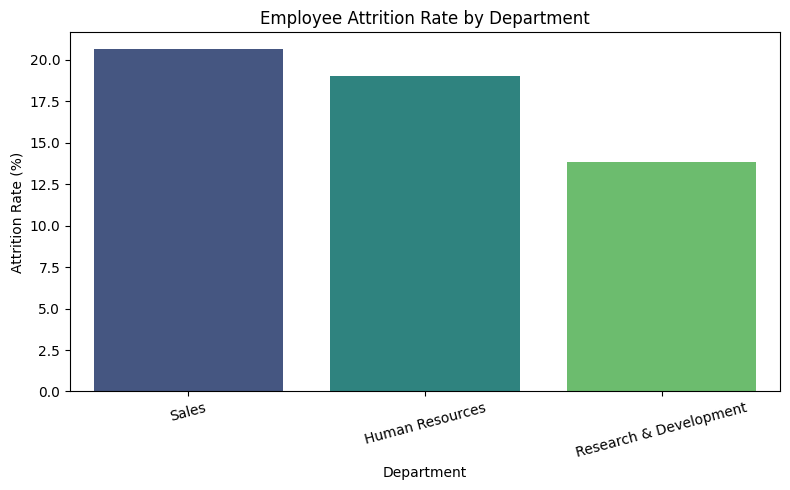

In [13]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=department_attrition,
    x="Department",
    y="Attrition Rate (%)",
    hue="Department",
    palette="viridis",
    legend=False
)

plt.title("Employee Attrition Rate by Department")
plt.xlabel("Department")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


### Analisis attrition berdasarkan overtime

`Pertanyaan bisnis`:  Apakah karyawan yang melakukan lembur memiliki attrition rate lebih tinggi dibandingkan karyawan yang tidak lembur?

In [14]:
overtime_attrition = (
    df.groupby("OverTime")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
    .reset_index(name="Attrition Rate (%)")
)

display(overtime_attrition)


,OverTime,Attrition Rate (%)
0,No,10.44
1,Yes,30.53


In [15]:
overtime_attrition["OverTime"] = overtime_attrition["OverTime"].replace({
    0: "No",
    1: "Yes"
})

display(overtime_attrition)


,OverTime,Attrition Rate (%)
0,No,10.44
1,Yes,30.53


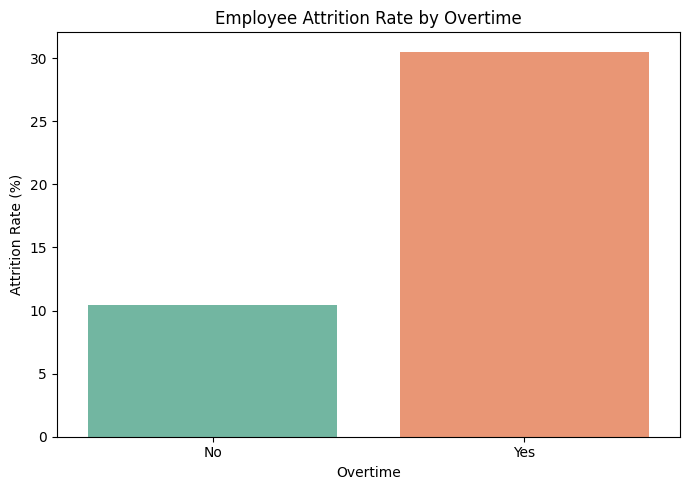

In [16]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=overtime_attrition,
    x="OverTime",
    y="Attrition Rate (%)",
    hue="OverTime",
    palette="Set2",
    legend=False
)

plt.title("Employee Attrition Rate by Overtime")
plt.xlabel("Overtime")
plt.ylabel("Attrition Rate (%)")
plt.tight_layout()
plt.show()


`Insight` : Karyawan yang bekerja lembur memiliki tingkat pengunduran diri yang lebih tinggi (30,53%) dibandingkan dengan karyawan yang tidak bekerja lembur (10,44%). Tingkat pengunduran diri di kalangan karyawan yang bekerja lembur adalah sekitar 2,92 kali lebih tinggi.

Temuan ini menunjukkan bahwa lembur mungkin menjadi faktor penting untuk ditelaah dalam strategi retensi karyawan. Namun, analisis ini hanya menunjukkan adanya keterkaitan, bukan hubungan sebab-akibat. Diperlukan analisis lebih lanjut untuk menentukan apakah hubungan tersebut dipengaruhi oleh faktor lain, seperti peran pekerjaan, pendapatan bulanan, atau kepuasan kerja.

### Analisis attrition berdasarkan job role

`Pertanyaan bisnis`: Jabatan mana yang memiliki attrition rate relatif tinggi dan mungkin perlu mendapat perhatian lebih lanjut dari tim HR?

In [17]:
jobrole_attrition = (
    df.groupby("JobRole")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
    .round(2)
    .reset_index(name="Attrition Rate (%)")
)

display(jobrole_attrition)


,JobRole,Attrition Rate (%)
0,Sales Representative,39.76
1,Laboratory Technician,23.94
2,Human Resources,23.08
3,Sales Executive,17.48
4,Research Scientist,16.10
5,Manufacturing Director,6.90
6,Healthcare Representative,6.87
7,Manager,4.90
8,Research Director,2.50


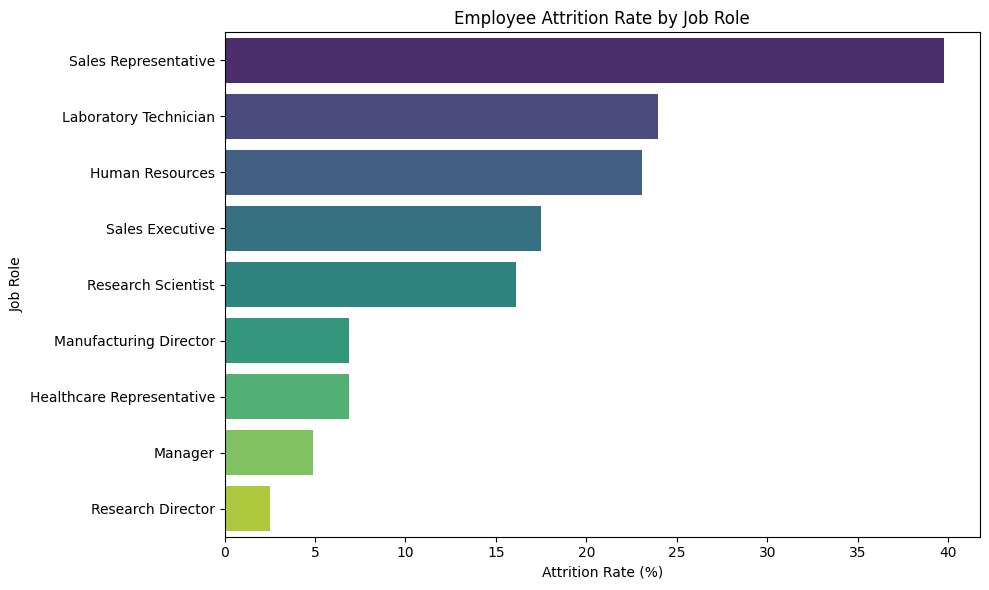

In [18]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=jobrole_attrition,
    x="Attrition Rate (%)",
    y="JobRole",
    hue="JobRole",
    palette="viridis",
    legend=False
)

plt.title("Employee Attrition Rate by Job Role")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Job Role")
plt.tight_layout()
plt.show()


`Insight`: Sales Representatives memiliki tingkat pengunduran diri tertinggi sebesar 39,76%, diikuti oleh Teknisi Laboratorium sebesar 23,94% dan HR sebesar 23,08%. Sebaliknya, Direktur Riset memiliki tingkat pengunduran diri terendah, yakni 2,50%.

Temuan ini menunjukkan bahwa tingkat pengunduran diri sangat bervariasi antarperan pekerjaan. Departemen SDM dapat memprioritaskan penyelidikan lebih lanjut terhadap peran-peran dengan tingkat pengunduran diri yang lebih tinggi, khususnya Perwakilan Penjualan, untuk memahami faktor-faktor yang mungkin berkontribusi. Akan tetapi, perbedaan ini tidak serta-merta menunjukkan penyebab pengunduran diri karyawan, dan jumlah karyawan dalam setiap peran juga perlu dipertimbangkan.

### Analisis gaji dan kepuasan kerja

`Pertanyaan bisnis`:

- Apakah karyawan yang keluar memiliki median gaji bulanan lebih rendah dibandingkan karyawan yang bertahan?
- Bagaimana tingkat kepuasan kerja (JobSatisfaction) berbeda antara kedua kelompok tersebut?

In [19]:
income_summary = (
    df.groupby("Attrition")["MonthlyIncome"]
    .agg(["count", "mean", "median"])
    .round(2)
    .reset_index()
)

display(income_summary)


,Attrition,count,mean,median
0,No,1233,6832.74,5204.0
1,Yes,237,4787.09,3202.0


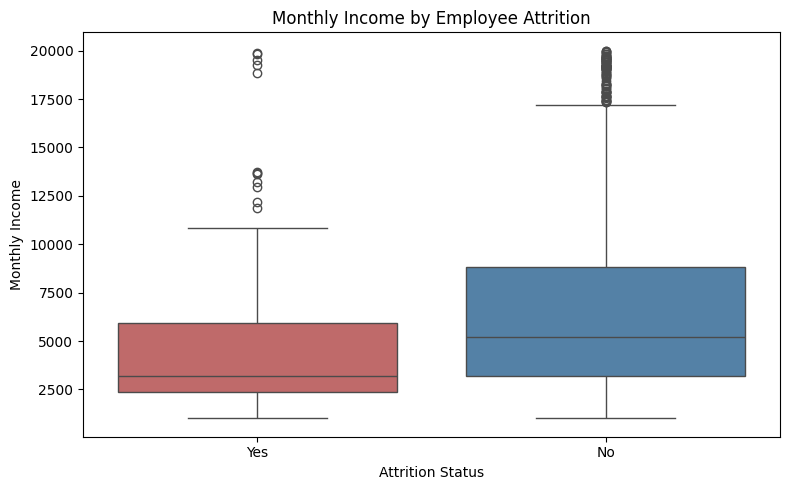

In [20]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Attrition",
    y="MonthlyIncome",
    hue="Attrition",
    palette={"No": "steelblue", "Yes": "indianred"},
    legend=False
)

plt.title("Monthly Income by Employee Attrition")
plt.xlabel("Attrition Status")
plt.ylabel("Monthly Income")
plt.tight_layout()
plt.show()


`Insight` : Karyawan yang meninggalkan perusahaan memiliki median pendapatan bulanan yang lebih rendah (3.202) dibandingkan dengan karyawan yang tetap bertahan (5.204). Rata-rata pendapatan bulanan mereka pun lebih rendah (4.787,09 dibandingkan dengan 6.832,74).

Pola ini menunjukkan bahwa kompensasi mungkin menjadi faktor yang relevan untuk diteliti dalam konteks retensi karyawan. Namun, perbedaan yang teramati ini tidak membuktikan bahwa pendapatan yang lebih rendah merupakan penyebab keluarnya karyawan. Faktor-faktor lain, seperti peran pekerjaan, senioritas, dan lama pengalaman kerja, mungkin turut berkontribusi terhadap perbedaan tersebut.

In [21]:
satisfaction_attrition = (
    df.groupby("JobSatisfaction")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
    .reset_index(name="Attrition Rate (%)")
)

satisfaction_labels = {
    1: "Low",
    2: "Medium",
    3: "High",
    4: "Very High"
}

satisfaction_attrition["Job Satisfaction"] = (
    satisfaction_attrition["JobSatisfaction"]
    .map(satisfaction_labels)
)

display(
    satisfaction_attrition[
        ["Job Satisfaction", "Attrition Rate (%)"]
    ]
)


,Job Satisfaction,Attrition Rate (%)
0,Low,22.84
1,Medium,16.43
2,High,16.52
3,Very High,11.33


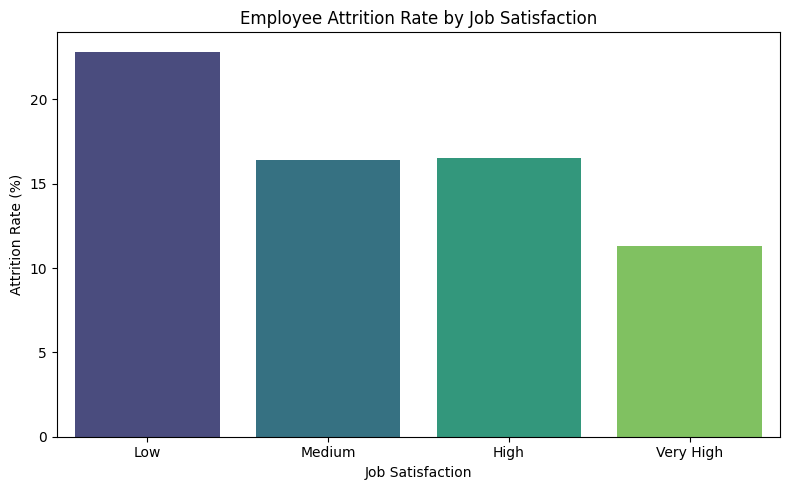

In [22]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=satisfaction_attrition,
    x="Job Satisfaction",
    y="Attrition Rate (%)",
    hue="Job Satisfaction",
    order=["Low", "Medium", "High", "Very High"],
    palette="viridis",
    legend=False
)

plt.title("Employee Attrition Rate by Job Satisfaction")
plt.xlabel("Job Satisfaction")
plt.ylabel("Attrition Rate (%)")
plt.tight_layout()
plt.show()


`Insight` : Karyawan dengan kepuasan kerja rendah memiliki tingkat pengunduran diri tertinggi, yakni sebesar 22,84%, sementara karyawan dengan kepuasan kerja sangat tinggi memiliki tingkat terendah, yaitu 11,33%. Selisih antara kedua kelompok tersebut adalah 11,51 poin persentase.

Temuan ini menunjukkan bahwa kepuasan kerja berkaitan dengan pengunduran diri karyawan dalam kumpulan data tersebut. Namun, hubungan ini tidak sepenuhnya linear; tingkat pengunduran diri bagi karyawan dengan kepuasan tinggi (16,52%) sedikit lebih tinggi dibandingkan dengan karyawan yang memiliki tingkat kepuasan menengah (16,43%). Analisis lebih lanjut diperlukan untuk memahami pengaruh dari karakteristik lain yang berkaitan dengan karyawan maupun pekerjaan.

### Masa kerja dan pengalaman karyawan

`Pertanyaan bisnis` : Apakah karyawan yang relatif baru bergabung memiliki attrition rate lebih tinggi dibandingkan karyawan yang sudah lama bekerja?

In [23]:
df["TenureGroup"] = pd.cut(
    df["YearsAtCompany"],
    bins=[-1, 1, 3, 5, 10, float("inf")],
    labels=[
        "0-1 years",
        "2-3 years",
        "4-5 years",
        "6-10 years",
        "Above 10 years"
    ]
)

tenure_attrition = (
    df.groupby("TenureGroup", observed=False)["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
    .reset_index(name="Attrition Rate (%)")
)

display(tenure_attrition)


,TenureGroup,Attrition Rate (%)
0,0-1 years,34.88
1,2-3 years,18.43
2,4-5 years,13.07
3,6-10 years,12.28
4,Above 10 years,8.13


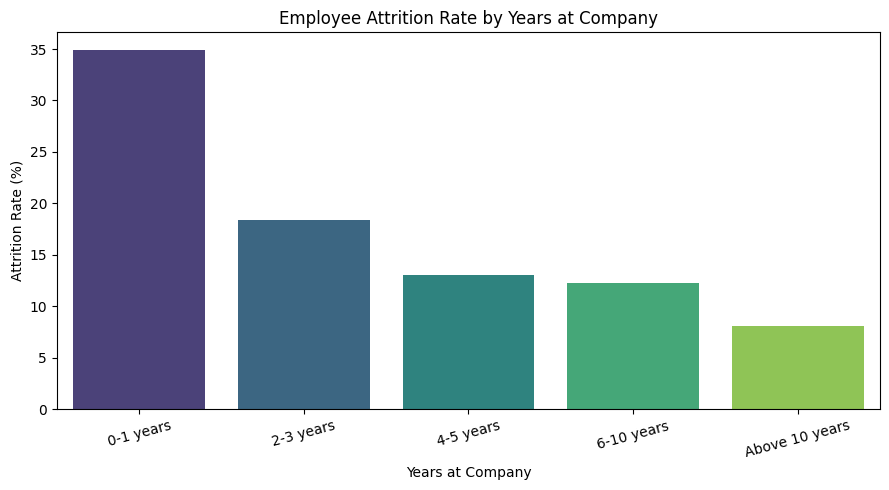

In [24]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=tenure_attrition,
    x="TenureGroup",
    y="Attrition Rate (%)",
    hue="TenureGroup",
    order=[
        "0-1 years",
        "2-3 years",
        "4-5 years",
        "6-10 years",
        "Above 10 years"
    ],
    palette="viridis",
    legend=False
)

plt.title("Employee Attrition Rate by Years at Company")
plt.xlabel("Years at Company")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


`Insight` : Karyawan dengan masa kerja 0–1 tahun memiliki tingkat pengunduran diri tertinggi, yakni sebesar 34,88%. Angka ini menurun pada kelompok dengan masa kerja yang lebih lama, hingga mencapai 8,13% di kalangan karyawan yang telah bekerja di perusahaan selama lebih dari 10 tahun.

Pola ini menunjukkan bahwa karyawan pada masa awal kerja mungkin memerlukan perhatian lebih dalam upaya retensi karyawan. Tim SDM dapat menelaah lebih lanjut mengenai efektivitas proses orientasi (*onboarding*), ekspektasi peran, kepuasan kerja, serta dukungan bagi karyawan di awal karier mereka.

## Final Insights & Business Recommendations

In [25]:
insights = pd.DataFrame({
    "Analysis": [
        "Overall Attrition",
        "Department",
        "Overtime",
        "Job Role",
        "Monthly Income",
        "Job Satisfaction",
        "Years at Company"
    ],
    "Key Finding": [
        "16.12% of employees left the company",
        "Sales had the highest department attrition rate (20.63%)",
        "Employees working overtime had a 30.53% attrition rate, compared with 10.44% for those not working overtime",
        "Sales Representatives had the highest job-role attrition rate (39.76%)",
        "Employees who left had a lower median monthly income (3,202 vs. 5,204)",
        "Low job satisfaction was associated with a higher attrition rate (22.84%) than very high satisfaction (11.33%)",
        "Employees with 0–1 years of tenure had the highest attrition rate (34.88%)"
    ]
})

display(insights)


,Analysis,Key Finding
0,Overall Attrition,16.12% of employees left the company
1,Department,Sales had the highest department attrition rat...
2,Overtime,Employees working overtime had a 30.53% attrit...
3,Job Role,Sales Representatives had the highest job-role...
4,Monthly Income,Employees who left had a lower median monthly ...
5,Job Satisfaction,Low job satisfaction was associated with a hig...
6,Years at Company,Employees with 0–1 years of tenure had the hig...


### Rekomendasi bisnis untuk HR

1. Evaluasi retensi di departemen Sales

Tinjau beban kerja, target penjualan, sistem insentif, dukungan manajer, dan peluang pengembangan karier. Faktor-faktor tersebut perlu diperiksa lebih lanjut, bukan diasumsikan sebagai penyebab.




2. Evaluasi kebijakan overtime

Attrition rate karyawan yang bekerja overtime mencapai 30,53%, dibandingkan 10,44% pada karyawan yang tidak bekerja overtime. HR dapat mengevaluasi jam kerja, distribusi beban kerja, dan keseimbangan kehidupan kerja.




3. Perkuat onboarding karyawan baru

Karyawan dengan masa kerja 0–1 tahun memiliki attrition rate tertinggi, yaitu 34,88%. HR dapat mengevaluasi program orientasi, kejelasan ekspektasi pekerjaan, mentoring, dan dukungan selama masa awal kerja.




4. Tinjau kompensasi dan kepuasan kerja

Karyawan yang keluar memiliki median pendapatan bulanan lebih rendah. HR dapat mengevaluasi kesesuaian kompensasi berdasarkan jabatan, senioritas, dan tanggung jawab, sekaligus menindaklanjuti hasil survei kepuasan karyawan.

In [26]:
# Export cleaned dataset for Tableau

df.to_csv(
    "employee_attrition_cleaned.csv",
    index=False
)


In [27]:
from google.colab import files

files.download("employee_attrition_cleaned.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>